# Hierarchical detection and tracking: a synthetic walkthrough

This notebook explains **how HodT works** on a small synthetic scene.

We declare a *family* of four levels:

```
mcs                root          MRC + MRI > 0.05 g/kg
├── updraft        child         W > 1 m/s,  searched inside each mcs
│   └── core       grandchild    W > 3 m/s,  searched inside each updraft, split on the W maxima
└── downdraft      child         W < -1 m/s, searched inside each mcs
```

In [13]:
%matplotlib inline
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo_root))

from examples.plot_synthetic import STYLE, draw_objects, legend, plot_scene, plot_step
from examples.synthetic_data import DT_S, DX_KM, make_frames
from src.tracking import AdvectedIoUTracker, HierarchicalTrackingEngine, TrackingLevel, detect_objects

## 1. The synthetic scene

- **MCS A** drifts eastward. It holds one broad updraft with **two cores** that move towards each other and **merge** around 12:15.
- **MCS B** is static, with one updraft and one core.
- A **false updraft** (strong W, no hydrometeors) sits south of MCS B. It is a trap: it looks like a core, but it is not in a MCS.

In [14]:
frames, time_values, timestamps_s = make_frames(n_times=8)
print(f"{len(frames)} timesteps: {time_values}")
frames[0]

8 timesteps: ['12:00', '12:05', '12:10', '12:15', '12:20', '12:25', '12:30', '12:35']


<xarray.Dataset> Size: 1MB
Dimensions:  (level: 20, y: 60, x: 100, level_w: 20)
Coordinates:
  * level    (level) float64 160B 250.0 750.0 1.25e+03 ... 9.25e+03 9.75e+03
  * level_w  (level_w) float64 160B 0.0 500.0 1e+03 ... 8.5e+03 9e+03 9.5e+03
Dimensions without coordinates: y, x
Data variables:
    W        (level, y, x) float32 480kB 2.789e-20 4.393e-20 ... 7.261e-35
    MRC      (level, y, x) float32 480kB 6.701e-07 8.872e-07 ... 0.0 0.0
    MRI      (level, y, x) float32 480kB 0.0 0.0 0.0 ... 2.187e-13 9.777e-14

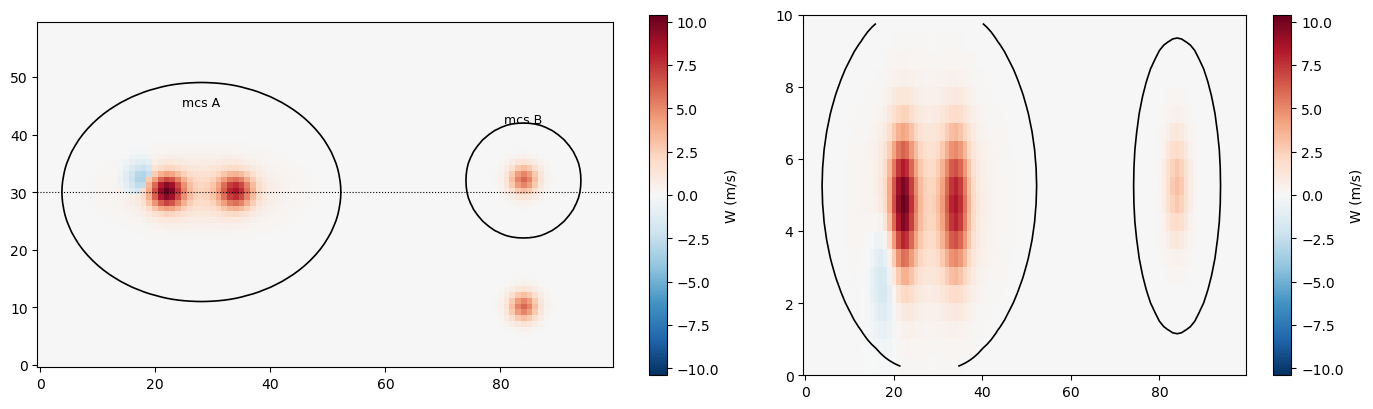

In [15]:
plot_scene(frames[0])

## 2. One rule per level

A rule says **what an object is**, nothing more. The detector applies it in four steps:

1. **mask**: all the `conditions` combined with AND (several variables in one condition are summed first, here `MRC + MRI`);
2. **objects**: 3D connected components of the mask;
3. **split** (optional): each component is cut along the maxima of a variable (recursive H-maxima watershed); this is how one updraft gives several cores;
4. **size filters**: `min_voxels`, `min_area_px`, `min_width_px`, `min_area_km2`.

The rules do not mention the hierarchy: the same `core` rule could be used at the root.

In [16]:
GRID = {"dx_km": DX_KM}  # no vertical clipping: the whole 0-10 km column is used

RULES = {
    "mcs": {
        **GRID,
        "conditions": [{"variables": ["MRC", "MRI"], "op": ">", "value": 0.05}],
        "min_voxels": 50,
    },
    "updraft": {
        **GRID,
        "conditions": [{"variables": "W", "op": ">", "value": 1.0}],
        "min_voxels": 20,
    },
    "downdraft": {
        **GRID,
        "conditions": [{"variables": "W", "op": "<", "value": -1.0}],
        "min_voxels": 20,
    },
    "core": {
        **GRID,
        "conditions": [{"variables": "W", "op": ">", "value": 3.0}],
        "split": "W",          # cut along the maxima of W
        "min_voxels": 10,
    },
}

## 3. Declaring the hierarchy

A `TrackingLevel` joins a name, a detector, a rule, a **parent** and, optionally, a tracker. The hierarchy is nothing more than the `parent_name` of each level:

- a **root** level (`parent_name=None`) is searched once over the whole domain;
- a **child** level is searched **once per parent object, inside that parent's voxels only**.

Levels are listed parents first (the engine checks it). `updraft` and `downdraft` are siblings: both are searched in the mcss, independently of each other.

Each level gets its own tracker. `max_speed_ms=30` bounds the search radius: a track can only be continued by an object whose centroid is within 30 m/s × 300 s = 9 km of its predicted position.

In [17]:
def tracker(name):
    return AdvectedIoUTracker(name, min_score=0.1, patience=1, dx_meters=DX_KM * 1000.0, max_speed_ms=30.0)


levels = [
    TrackingLevel("mcs",     detect_objects, parent_name=None,      params=RULES["mcs"],     tracker=tracker("mcs")),
    TrackingLevel("updraft",   detect_objects, parent_name="mcs",   params=RULES["updraft"],   tracker=tracker("updraft")),
    TrackingLevel("downdraft", detect_objects, parent_name="mcs",   params=RULES["downdraft"], tracker=tracker("downdraft")),
    TrackingLevel("core",      detect_objects, parent_name="updraft", params=RULES["core"],      tracker=tracker("core")),
]
level_names = [lvl.name for lvl in levels]
engine = HierarchicalTrackingEngine(levels)

## 4. Detection and tracking

`run_and_track` detects every level at every timestep, then feeds each tracker in chronological order.

In [18]:
out = engine.run_and_track(frames, time_values=time_values, timestamps_s=timestamps_s)
results, tracks = out["results_by_time"], out["tracks_by_level"]

pd.DataFrame(
    {name: [len(step["levels"][name]) for step in results] for name in level_names},
    index=pd.Index(time_values, name="time"),
)

,mcs,updraft,downdraft,core
time,,,,
12:00,2,2,1,3
12:05,2,2,1,3
12:10,2,2,1,3
12:15,2,2,1,2
12:20,2,2,1,2
12:25,2,2,1,2
12:30,2,2,1,2
12:35,2,2,1,2


## 6. Tracking in time

In [19]:
pd.DataFrame(
    [{"level": name, "track": tid, "start": tr["start_time"], "end": tr["end_time"], "steps": len(tr["history"]),
      "events": "; ".join(f"{e['type']} at {e['time']}" + (f" into {e['into']}" if "into" in e else "") for e in tr.get("events", []))}
     for name in level_names for tid, tr in tracks[name].items()]
)

,level,track,start,end,steps,events
0,mcs,mcs_0001,12:00,12:35,8,
1,mcs,mcs_0002,12:00,12:35,8,
2,updraft,updraft_0001,12:00,12:35,8,
3,updraft,updraft_0002,12:00,12:35,8,
4,downdraft,downdraft_0001,12:00,12:35,8,
5,core,core_0001,12:00,12:10,3,merge at 12:15 into core_0002
6,core,core_0002,12:00,12:35,8,absorbed at 12:15
7,core,core_0003,12:00,12:35,8,


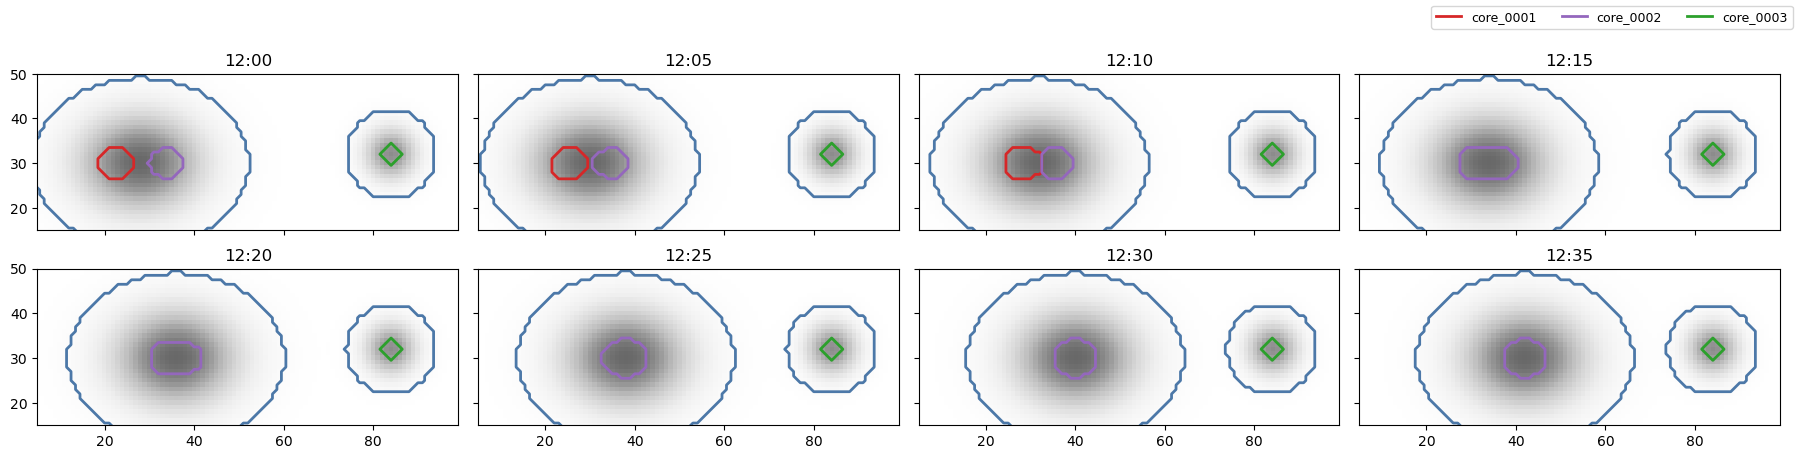

In [20]:
track_of = {obj["object_id"]: tid for name in level_names for tid, tr in tracks[name].items() for obj in tr["history"]}
core_track_ids = sorted(tracks["core"])
palette = ["#d62728", "#9467bd", "#2ca02c", "#e377c2", "#8c564b"]  # no blue: blue is the cloud outline
track_colors = {tid: palette[i % len(palette)] for i, tid in enumerate(core_track_ids)}

fig, axes = plt.subplots(2, 4, figsize=(18, 4.6), sharex=True, sharey=True)
for ax, frame, step in zip(axes.flat, frames, results):
    hydro = (frame["MRC"].values + frame["MRI"].values).max(axis=0)
    ax.imshow(hydro, origin="lower", cmap="Greys", vmin=0, vmax=1.5)
    draw_objects(ax, {"mcs": step["levels"]["mcs"]}, hydro.shape)
    for core in step["levels"]["core"]:
        tid = track_of[core["object_id"]]
        style = {"core": dict(color=track_colors[tid], lw=2.0, ls="-")}
        draw_objects(ax, {"core": [core]}, hydro.shape, styles=style)
    ax.set_title(step["time"])
    ax.set_xlim(5, 99)
    ax.set_ylim(15, 50)
fig.legend(handles=[plt.Line2D([], [], color=c, lw=2, label=t) for t, c in track_colors.items()],
           loc="upper right", ncol=len(track_colors), fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()